In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import correlate, correlation_lags
from pathlib import Path
from scipy.ndimage import gaussian_filter1d
from itertools import combinations, permutations

In [3]:
# relevant files
trials = np.array(["Clip0001_1C_4N_G_1", "Clip0002_1C_4N_G_2", "Clip0006_1C_4N_G_6", "Clip0009_1C_4N_G_8", "Clip0011_1C_4N_G_10", "Clip0012_1C_4N_T_1", "Clip0020_1C_4N_T_8", "Clip0023_1C_4N_E2_1", "Clip0025_1C_4N_E2_3", "Clip0042_1C_4N_E4_10", "Clip0048_1C_4N_E9_6", "Clip0058_1C_4N_E7_6", "Clip0069_1C_4N_E3_7", "Clip0070_1C_4N_E3_8", "Clip0074_1C_4N_E8_1", "Clip0078_1C_4N_E8_5", "Clip0079_1C_4N_E8_6", "Clip0079_E7_1", "Clip0080_1C_4N_E8_7", "Clip0081_E7_3", "Clip0082_1C_4N_E8_9", "Clip0083_1C_4N_E8_10", "Clip0083_E7_5", "Clip0092_E2_4", "Clip0095_E2_7", "Clip0107_E3_9"])
trials = np.delete(trials, [3,5,6])
parent_dir = Path('/home/hck03/Documents/MS_thesis/tracking_output/1c_4n_faulty')
no_files = len(trials)
N = 5
light_on_frame = [89, 46, 90, 64, 32, 74, 58, 80, 46, 55, 29, 44, 38, 38, 38, 41, 29, 88, 55, 43, 45, 40, 34, 38, 53, 37]
light_on_frame = np.delete(light_on_frame, [3,5,6])
max_lag = 75

In [4]:
l_lim = 22
r_lim = 30.5

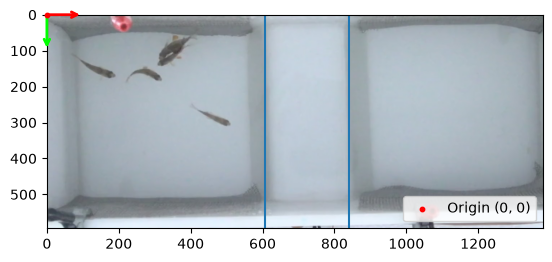

In [5]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

img = mpimg.imread("/home/hck03/Pictures/Haruna screenshots/Clip0001_1C_4N_G_1-0001.jpg")

fig, ax = plt.subplots()
ax.imshow(img)

ax.scatter(0, 0, color='red', s=10, zorder=5, clip_on=False, label='Origin (0, 0)')

ax.annotate('', xy=(100, 0), xytext=(0, 0),
            arrowprops=dict(arrowstyle='->', color='red', lw=2), annotation_clip=False)
ax.annotate('', xy=(0, 100), xytext=(0, 0),
            arrowprops=dict(arrowstyle='->', color='lime', lw=2), annotation_clip=False)
ax.axvline(x=(l_lim / 0.03630))
ax.axvline(x=(r_lim / 0.03630))

ax.legend(loc='lower right')
plt.show()

In [6]:

# for f in trials:
#     # print(f)
#     fp = parent_dir / f / 'data' / 'clean_tracks.npy'
#     # print(fp)
#     d = np.load(fp)
#     print(d.shape)
#     nans_per_row = np.isnan(d).sum(axis=(1,2))
#     print(f, nans_per_row)

In [7]:
shapes = [np.load(parent_dir / f / 'data' / 'clean_tracks.npy').shape for f in trials]
max_len = max(s[1] for s in shapes)

combined_trials = np.full((len(trials), 5, max_len, 2), np.nan, dtype=np.float64)

for i, f in enumerate(trials):
    fp = parent_dir / f / 'data' / 'clean_tracks.npy'
    d = np.load(fp)
    combined_trials[i, :, :d.shape[1], :] = d

In [8]:
no_of_frames = combined_trials.shape[2]
no_of_trials = combined_trials.shape[0]
no_ind = combined_trials.shape[1]

crossing_rank_array = np.zeros((no_ind, no_of_trials), dtype=object)

for i in range(combined_trials.shape[0]):
# i = 5
    trial_traj = np.squeeze(combined_trials[i,:,:,:])
    # print(trial_traj.shape)
    t_crossing = np.full(no_ind, np.inf)
    for ind in range(no_ind):
        x_coord = trial_traj[ind,:, 0]
        # valid_idx = np.where(~np.isnan(x_coord))[0]
        # print(x_coord.shape)
        # if len(valid_idx) == 0:
        #     continue
        # valid_x = x_coord[valid_idx]
        # # start_x = x_coord[valid_idx[0]]
        # if valid_x[0] > r_lim:
        #     # print(i, "hello from the right side")
        #     idx = valid_idx[0]
        #     while idx < len(x_coord) and x_coord[idx] > l_lim:
        #         # print(idx, x_coord[idx])
        #         idx += 1
        #     t_crossing[ind] = idx
        #     # print(ind, "left limit = ", x_lim_l, f"our crossing x at {idx+light_on_frame-1} = ", x_coord[idx])
        # # if start_x > r_lim:
        # #     crossed_frames = np.where(x_coord <= l_lim)[0]
        # else:
        #     idx = 0
        #     # print(i, "hello from the left side")
        #     while idx < len(x_coord) and x_coord[idx] < r_lim:
        #         # print(idx, x_coord[idx])
        #         idx += 1
        #     t_crossing[ind] = idx
        # #     crossed_frames = np.where(x_coord >= r_lim)[0]
        # # if len(crossed_frames) > 0:
        # #     t_crossing[ind] = crossed_frames[0]

        valid_mask = ~np.isnan(x_coord)

        if not np.any(valid_mask):
            print('hi')
            t_crossing[ind] = np.nan
        else:
            first_valid_idx = int(np.argmax(valid_mask)) 
            x_clean = x_coord[valid_mask]
            if x_clean[0] >= r_lim:
                crossed = np.where(x_clean < l_lim)[0]
                # print('hello from right', crossed)      
            elif x_clean[0] <= l_lim:  
                crossed = np.where(x_clean > r_lim)[0]
                # print('hello from left', crossed)   
            else:                         
                # print('hello from the center')
                crossed = np.where((x_clean < l_lim) | (x_clean > r_lim))[0]

            t_crossing[ind] = (first_valid_idx + crossed[0]) if len(crossed) > 0 else np.nan
            # print(i, ind, t_crossing[ind])#, len(crossed))

    ids = list(range(1,no_ind+1))
    id_t_tuples = list(zip(ids, t_crossing.tolist()))
    crossing_rank = sorted(id_t_tuples, key=lambda x: x[1])
    # print(type(crossing_rank[0]))
    for j in range(no_ind):
        crossing_rank_array[j, i] = crossing_rank[j]

In [9]:
for i in range(no_of_trials):
    shuffle = [int(crossing_rank_array[:,i][j][0]-1) for j in range(no_ind)]
    # print(grand_trajectories_array.shape)
    combined_trials[i] = combined_trials[i][shuffle,:,:]

In [10]:
# getting kinematics from the data
combined_vel = np.gradient(combined_trials, axis=2)
combined_speed = np.linalg.norm(combined_vel, axis=3, ord=2)
# combined_speed_smooth = gaussian_filter1d(combined_speed, sigma=0.5, axis=2)

In [11]:
combined_speed_smooth = np.full(combined_speed.shape, np.nan)
for i in range(no_files):
    intermediate_1 = np.full((no_ind, no_of_frames), np.nan)
    for j in range(no_ind):
        temp_speed_ij = combined_speed[i,j,:]
        valid_mask = ~np.isnan(temp_speed_ij)
        smooth_speed = gaussian_filter1d(temp_speed_ij[valid_mask], sigma=3)
        intermediate_1[j, valid_mask] = smooth_speed
    combined_speed_smooth[i,...] = intermediate_1
        

In [12]:
def crosscorr(speed_x, speed_y, max_lag, min_lag=1):
    speed_x = np.asarray(speed_x, dtype=float)
    speed_y = np.asarray(speed_y, dtype=float)
    if len(speed_x) != len(speed_y):
        raise ValueError("speed_x and speed_y must have the same length.")
    max_lag = max(int(max_lag), min_lag)
    speed_x = np.nan_to_num(speed_x - np.nanmean(speed_x), nan=0.0)
    speed_y = np.nan_to_num(speed_y - np.nanmean(speed_y), nan=0.0)

    lags = np.arange(-max_lag, max_lag+1)
    C_ij = np.zeros(len(lags))
    for i, tau in enumerate(lags):
        if tau > 0:
            x_seg, y_seg = speed_x[:-tau], speed_y[tau:]
        elif tau < 0:
            x_seg, y_seg = speed_x[-tau:], speed_y[:tau]
        else:
            x_seg, y_seg = speed_x, speed_y
        denom = np.sqrt(np.sum(x_seg**2) * np.sum(y_seg**2))
        if not np.isclose(denom, 0.0):
            C_ij[i] = np.nansum(x_seg * y_seg) / denom
    return C_ij, lags   
   
def which_phase_data(speed_array, trial_id, phase_count=1):
    # if trial_id == trial_id_2:
    lof = light_on_frame[trial_id]
    last_fish_cross_time = int(crossing_rank_array[-1, trial_id][1])
    if phase_count == 0:
        valid_speed = speed_array[trial_id, :, :lof]
        t_diff = valid_speed.shape[1]
    elif phase_count == 1:
        valid_speed = speed_array[trial_id, :, lof:last_fish_cross_time+1]
        t_diff = valid_speed.shape[1]
    elif phase_count == 2:
        valid_speed = speed_array[trial_id, :, last_fish_cross_time+1:]
        t_diff = valid_speed.shape[1]
    return valid_speed, t_diff

In [13]:
combined_speed_smooth.shape

(23, 5, 1882)

In [31]:
# within trial correlations between all pairs of individuals
fish_ids = np.arange(N)
possible_pairs = list(combinations(fish_ids, 2))

min_ts_length = 10
min_lag = 10

phase_count = 1

grand_cc_array = np.full((len(possible_pairs), no_files, no_files), np.nan)
grand_lag_array = np.full((len(possible_pairs), no_files, no_files), np.nan)

for l, (i,j) in enumerate(possible_pairs):
# for i in range(N):
#     for j in range(N):
    # pair = (i, j)
    pair_cc_temp = np.full((no_files, no_files), np.nan)
    pair_lag_temp = np.full((no_files, no_files), np.nan)
    for m in range(no_files):
        valid_speed_m, tdiff_m = which_phase_data(speed_array=combined_speed_smooth, trial_id=m, phase_count=1)
        if tdiff_m < min_ts_length:
            continue
        for n in range(no_files):
            # print(n)
            valid_speed_n, tdiff_n = which_phase_data(combined_speed_smooth, n, phase_count=1)
            if tdiff_n < min_ts_length:
                continue
            pert_time = min(tdiff_m, tdiff_n)
            speed_m_trunc = valid_speed_m[:, :pert_time]
            speed_n_trunc = valid_speed_n[:, :pert_time]
            # find cross correlation
            speed_i = speed_m_trunc[i, :] 
            speed_j = speed_n_trunc[j, :]
            cc, lags = crosscorr(speed_i, speed_j, max_lag)
            if len(cc) == 0:
                continue
            max_idx = np.argmax(cc)
            best_cc = cc[max_idx]
            best_lag = lags[max_idx]
            # print(best_lag)

            if m == n:
                if abs(best_lag) >= min_lag:
                    pair_cc_temp[m, n] = best_cc
                    pair_lag_temp[m, n] = best_lag
            else:
                if abs(best_lag) >= min_lag:
                    pair_cc_temp[m, n] = best_cc
                    pair_lag_temp[m, n] = best_lag

    grand_cc_array[l, ...] = pair_cc_temp
    grand_lag_array[l, ...] = pair_lag_temp


In [ ]:
grand_cc_array

In [39]:
# finding significance of correlation
# real_cc = [grand_cc_array[:, i, i] for i in range(no_files)]
rng = np.random.default_rng(seed=42)
no_permutations = 10000
p_val_cutoff = 0.05

# significant_edges = []  

graph_edges = []
edge_weights = []

# for i in range(N):
#     for j in range(N):
for l, (i,j) in enumerate(possible_pairs):
    cc_matrix = grand_cc_array[l, ...]
    lag_matrix = grand_lag_array[l, ...]

    diag_cc = np.diag(cc_matrix)
    diag_lag = np.diag(lag_matrix)

    valid_rows = np.where(~np.isnan(diag_cc))[0]
    K = len(valid_rows)
    if K == 0:
        continue
    # print(K)/
    mean_cc = np.mean(diag_cc[valid_rows])
    # print(mean_cc)
    mean_lag = np.mean(diag_lag[valid_rows])

    perm_means = np.zeros(no_permutations)
    for row_idx in valid_rows:
        # Pool of valid (non-NaN) correlations in this trial's row
        row_pool = cc_matrix[row_idx, ~np.isnan(cc_matrix[row_idx])]
        perm_means += rng.choice(row_pool, size=no_permutations, replace=True)
    perm_means /= K


    pval = np.mean(perm_means > mean_cc)
    print(i, j, pval, mean_lag)
    if pval <= p_val_cutoff:
        graph_edges.append((i,j))
        edge_weights.append(np.round(mean_cc, 3))
        

0 1 0.0048 4.7368421052631575
0 2 0.0941 28.38095238095238
0 3 0.5744 10.695652173913043
0 4 0.4651 14.952380952380953
1 2 0.0 31.863636363636363
1 3 0.1896 32.95238095238095
1 4 0.0712 38.26086956521739
2 3 0.0 40.05882352941177
2 4 0.0043 30.1
3 4 0.0 26.904761904761905


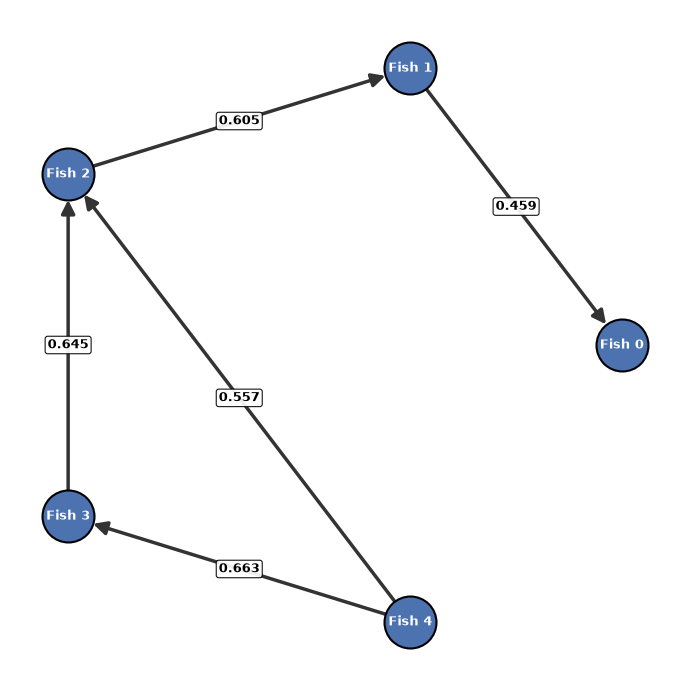

In [41]:
import matplotlib.pyplot as plt
import networkx as nx

def draw_curved_edge_labels(ax, G, pos, edgelist, rad=0.0, t=0.5, edge_color="#333333", font_size=9):
    """Places edge labels directly on top of straight or arc3-curved edges."""
    for u, v in edgelist:
        if "lag" not in G[u][v]:
            continue
        x1, y1 = pos[u]
        x2, y2 = pos[v]

        # Matplotlib's Arc3 quadratic Bezier control point
        dx, dy = x2 - x1, y2 - y1
        cnx = (x1 + x2) / 2.0 + rad * dy
        cny = (y1 + y2) / 2.0 - rad * dx

        # Point along the curve at parameter t (t=0.5 is the apex of the arc)
        lx = (1 - t) ** 2 * x1 + 2 * (1 - t) * t * cnx + t ** 2 * x2
        ly = (1 - t) ** 2 * y1 + 2 * (1 - t) * t * cny + t ** 2 * y2

        ax.text(
            lx, ly,
            f"{G[u][v]['lag']}",
            fontsize=font_size,
            color='k',
            fontweight="bold",
            ha="center",
            va="center",
            zorder=5,
            bbox=dict(
                boxstyle="round,pad=0.2",
                facecolor="white",
                # edgecolor=edge_color,
                linewidth=0.8,
                alpha=0.92
            )
        )

# --- Build and plot the graph ---
G = nx.DiGraph()
G.add_nodes_from(range(N))
for (leader, follower), lag in zip(graph_edges, edge_weights):
    G.add_edge(follower, leader, lag=lag)

fig, ax = plt.subplots(figsize=(7, 7))
pos = nx.circular_layout(G)

nx.draw_networkx_nodes(
    G, pos, ax=ax,
    node_size=1400,
    node_color="#4C72B0",
    edgecolors="black",
    linewidths=1.5
)
nx.draw_networkx_labels(
    G, pos, ax=ax,
    labels={i: f"Fish {i}" for i in G.nodes()},
    font_color="white",
    font_weight="bold",
    font_size='9'
)

bidirectional_edges = [(u, v) for (u, v) in G.edges() if (v, u) in G.edges()]
unidirectional_edges = [(u, v) for (u, v) in G.edges() if (v, u) not in G.edges()]

# 1. One-way edges (rad = 0.0) + labels directly on the line
if unidirectional_edges:
    nx.draw_networkx_edges(
        G, pos, ax=ax,
        edgelist=unidirectional_edges,
        width=2.5,
        edge_color="#333333",
        arrows=True,
        arrowstyle="-|>",
        arrowsize=20,
        node_size=1400,
        connectionstyle="arc3,rad=0.0"
    )
    draw_curved_edge_labels(
        ax, G, pos, unidirectional_edges,
        rad=0.0, edge_color="#333333"
    )

# 2. Two-way edges (rad = 0.2) + labels directly on each curved arc
if bidirectional_edges:
    rad_bi = 0.2
    nx.draw_networkx_edges(
        G, pos, ax=ax,
        edgelist=bidirectional_edges,
        width=2.5,
        edge_color="#D95F02",
        arrows=True,
        arrowstyle="-|>",
        arrowsize=20,
        node_size=1400,
        connectionstyle=f"arc3,rad={rad_bi}"
    )
    draw_curved_edge_labels(
        ax, G, pos, bidirectional_edges,
        rad=rad_bi, edge_color="#D95F02"
    )

ax.axis("off")
plt.tight_layout()
plt.show()

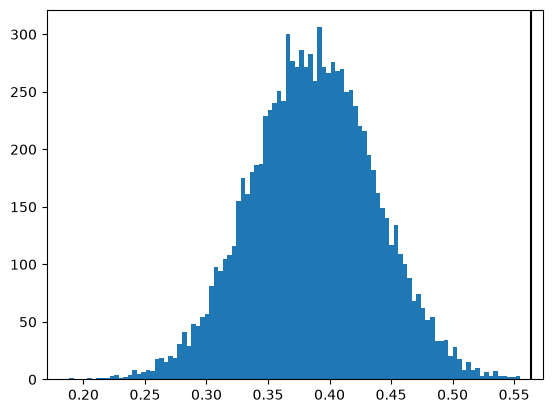

In [19]:
plt.hist(perm_means, bins=100)
plt.axvline(x = mean_cc, color='k')
plt.show()

In [ ]:
# graveyard
# def crosscorr(x, y, num_lags):
#     x = np.asarray(x, dtype=float)
#     y = np.asarray(y, dtype=float)

#     max_possible_lag = min(len(x), len(y)) - 1
#     if max_possible_lag < 0:
#         return np.array([]), np.array([])
#     num_lags = min(int(num_lags), max_possible_lag)

#     x = np.nan_to_num(x - np.nanmean(x), nan=0.0)
#     y = np.nan_to_num(y - np.nanmean(y), nan=0.0)

#     corr = correlate(x, y, mode='full')
#     lags = correlation_lags(len(x), len(y), mode='full')
#     denom = np.sqrt(np.sum(x**2) * np.sum(y**2))

#     if np.isclose(denom, 0.0):
#         corr = np.zeros_like(corr)
#     else:
#         corr = corr / denom

    # mask = (lags >= -num_lags) & (lags <= num_lags)
    # return corr[mask], lags[mask]